# Spaceship Titanic

## Preliminaries

### Os

In [1]:
cd ..

/home/alex/tmp/kaggle-spaceship-titanic


### Imports

In [2]:
from src.imports import *
from src.transformers import *
from src.helpers import *
from src.vars import *
from src.pca import Pca
from src.tools import *

### Data

In [3]:
train = pd.read_csv("data/source/train.csv")
test = pd.read_csv("data/source/test.csv")

## Exploratory Data Analysis

### Display

In [4]:
train.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [5]:
train.sample(10)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
1106,1170_01,Earth,False,E/83/S,TRAPPIST-1e,23.0,False,0.0,0.0,279.0,0.0,512.0,Samie Mcneiley,False
4474,4756_02,Europa,True,C/188/S,55 Cancri e,54.0,False,0.0,0.0,NaN,0.0,0.0,Beidus Gealloyalt,True
2725,2925_02,Mars,True,F/609/P,55 Cancri e,23.0,False,0.0,0.0,0.0,0.0,0.0,Goleer Minen,True
7718,8233_02,Earth,False,F/1575/S,TRAPPIST-1e,37.0,False,72.0,0.0,18.0,0.0,809.0,Stevey Balderts,False
2550,2736_01,Mars,False,D/81/P,TRAPPIST-1e,27.0,True,1709.0,4.0,24.0,0.0,0.0,Mark Prity,False
8404,8986_01,Earth,False,E/590/S,TRAPPIST-1e,19.0,False,0.0,810.0,21.0,788.0,NaN,Neilda Kirklander,False
2489,2670_01,Earth,False,G/432/P,TRAPPIST-1e,20.0,False,4.0,790.0,0.0,15.0,0.0,Glenna Leodger,False
5113,5465_03,Mars,True,F/1132/P,TRAPPIST-1e,6.0,False,0.0,0.0,0.0,0.0,0.0,Jacks Chité,True
475,0512_01,Europa,False,D/18/S,55 Cancri e,32.0,False,0.0,5755.0,0.0,59.0,122.0,Sadirak Nateansive,True
3569,3842_01,Earth,False,F/794/P,55 Cancri e,41.0,False,312.0,89.0,44.0,0.0,252.0,Lynnee Vinston,False


In [6]:
train.tail(10)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
8683,9272_02,Earth,False,F/1894/P,TRAPPIST-1e,21.0,False,86.0,3.0,149.0,208.0,329.0,Gordo Simson,False
8684,9274_01,NaN,True,G/1508/P,TRAPPIST-1e,23.0,False,0.0,0.0,0.0,0.0,0.0,Chelsa Bullisey,True
8685,9275_01,Europa,False,A/97/P,TRAPPIST-1e,0.0,False,0.0,0.0,0.0,0.0,0.0,Polaton Conable,True
8686,9275_02,Europa,False,A/97/P,TRAPPIST-1e,32.0,False,1.0,1146.0,0.0,50.0,34.0,Diram Conable,False
8687,9275_03,Europa,NaN,A/97/P,TRAPPIST-1e,30.0,False,0.0,3208.0,0.0,2.0,330.0,Atlasym Conable,True
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False
8692,9280_02,Europa,False,E/608/S,TRAPPIST-1e,44.0,False,126.0,4688.0,0.0,0.0,12.0,Propsh Hontichre,True


## Structure 

In [7]:
train.shape

(8693, 14)

In [8]:
train.dtypes

PassengerId      object
HomePlanet       object
CryoSleep        object
Cabin            object
Destination      object
Age             float64
VIP              object
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Name             object
Transported        bool
dtype: object

In [9]:
train.dtypes.value_counts()

object     7
float64    6
bool       1
Name: count, dtype: int64

In [10]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [11]:
train.select_dtypes(exclude=np.number).nunique().sort_values(ascending=False)

PassengerId    8693
Name           8473
Cabin          6560
HomePlanet        3
Destination       3
CryoSleep         2
VIP               2
Transported       2
dtype: int64

## Nan and Unique

In [12]:
train.isna().mean(axis=0).sort_values(ascending=False).round(2)

CryoSleep       0.02
ShoppingMall    0.02
VIP             0.02
HomePlanet      0.02
Name            0.02
Cabin           0.02
VRDeck          0.02
FoodCourt       0.02
Spa             0.02
Destination     0.02
RoomService     0.02
Age             0.02
PassengerId     0.00
Transported     0.00
dtype: float64

In [13]:
tmp = train.isna().mean(axis=1).sort_values(ascending=False).round(2)
tmp[tmp > 0]

3882    0.21
7211    0.21
2639    0.21
4164    0.21
7682    0.21
        ... 
4347    0.07
7       0.07
8687    0.07
1307    0.07
23      0.07
Length: 2087, dtype: float64

## Data Inspection

In [14]:
train.describe(include=np.number).round(0)

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.0,8512.0,8510.0,8485.0,8510.0,8505.0
mean,29.0,225.0,458.0,174.0,311.0,305.0
std,14.0,667.0,1611.0,605.0,1137.0,1146.0
min,0.0,0.0,0.0,0.0,0.0,0.0
25%,19.0,0.0,0.0,0.0,0.0,0.0
50%,27.0,0.0,0.0,0.0,0.0,0.0
75%,38.0,47.0,76.0,27.0,59.0,46.0
max,79.0,14327.0,29813.0,23492.0,22408.0,24133.0


In [15]:
dd = train.describe(exclude=np.number).round(2)
dd

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,VIP,Name,Transported
count,8693,8492,8476,8494,8511,8490,8493,8693
unique,8693,3,2,6560,3,2,8473,2
top,0001_01,Earth,False,G/734/S,TRAPPIST-1e,False,Gollux Reedall,True
freq,1,4602,5439,8,5915,8291,2,4378


In [16]:
train.Transported = train.Transported.astype(int)
train

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,0
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,1
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,0
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,0
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,0
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,0
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,1
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,0


In [17]:
X = train.drop("Transported", axis=1)
y = train["Transported"]

In [18]:
dd = dd.T
dd

,count,unique,top,freq
PassengerId,8693,8693,0001_01,1
HomePlanet,8492,3,Earth,4602
CryoSleep,8476,2,False,5439
Cabin,8494,6560,G/734/S,8
Destination,8511,3,TRAPPIST-1e,5915
VIP,8490,2,False,8291
Name,8493,8473,Gollux Reedall,2
Transported,8693,2,True,4378


In [19]:
DISPLAY = True
FRAC = 0.1

<Figure size 1000x1000 with 0 Axes>

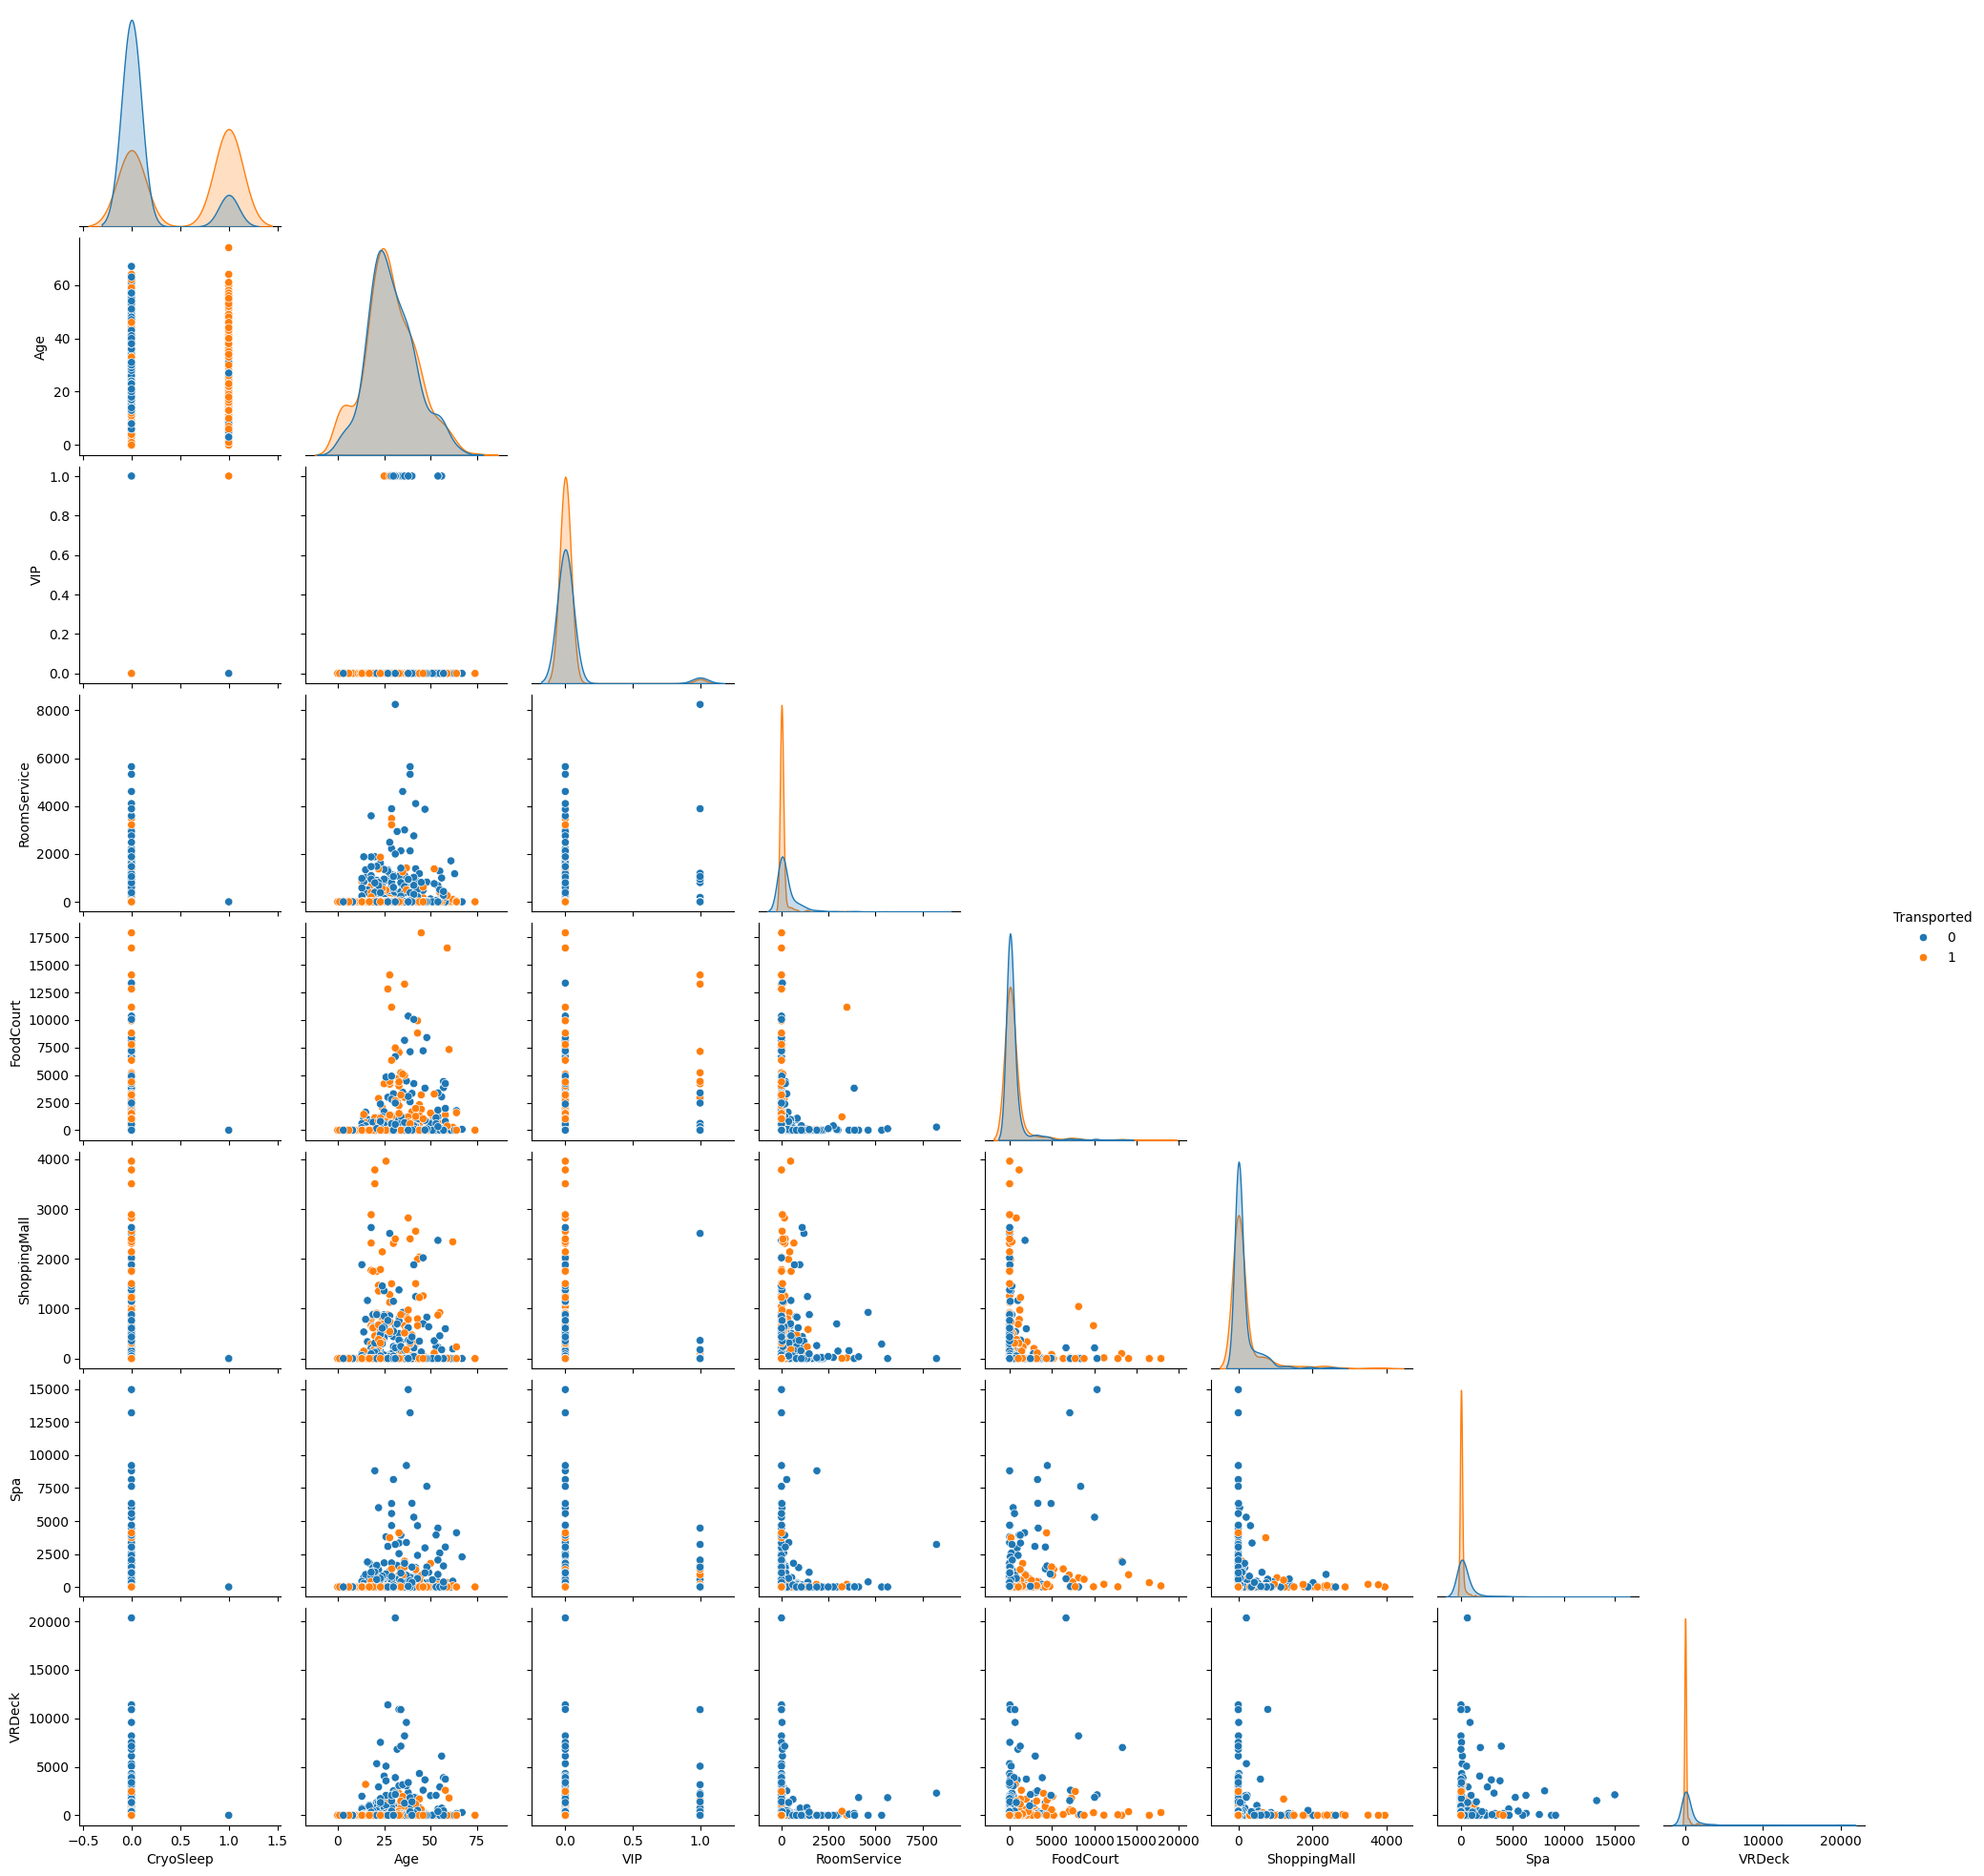

In [20]:
if DISPLAY:
    plt.figure(figsize=(10, 10))
    sns.pairplot(train.sample(frac=FRAC), corner=True, hue="Transported")

## Preprocess

In [ ]:
_train = preprocess(pipeline, train)
_train

In [ ]:
num = _train.loc[:, [i for i in _train.columns if i.startswith("passthrough")]]
num

In [ ]:
FRAC = 0.1
if DISPLAY:
    plt.figure(figsize=(16, 10))
    sns.pairplot(num.sample(frac=FRAC), corner=True, hue="num__Transported")

In [ ]:
corr = num.select_dtypes(include=np.number).corr()
corr

In [ ]:
plt.figure(figsize=(16, 10))
corr = num.select_dtypes(include=np.number).corr()
mask = np.triu(corr)
sns.heatmap(corr, annot=True, fmt=".2f", mask=mask, cmap="coolwarm", vmin=-1, vmax=1)

In [ ]:
acp = Pca(num.drop(columns="num__Transported"))

In [ ]:
acp._variance

In [ ]:
acp._pcs

In [ ]:
acp.variance()

In [ ]:
acp.pcs()

In [ ]:
acp.correlation_graph([0, 1])

In [ ]:
acp.correlation_graph([0, 2])

In [ ]:
acp.correlation_graph([1, 2])

In [ ]:
acp.factorial_planes([0, 1, 2])